# Ноутбук 1 (Трек A): Классические модели, Лестница биофизических признаков, LUPI-калибровка и EM-адаптация Саеренса ($N=426$)

**Научные задачи Трека A:**
1. **Контракт данных и заморозка сплитов (`00_Foundation`):** Верификация 23 файлов из `data/`, проверка нулевых утечек и генерация единых индексов кросс-валидации `Train_5x5_CV.json` ($n=82$, 25 фолдов) и `CQ_10x5_CV.json` ($n=35$, 50 фолдов) для всех 4 ноутбуков проекта.
2. **Эксперимент A1 (Базовые панели и Single-Patient инвариантность):**
   - Сравнение 5 выровненных маркеров (`Aligned_5`, протокол Zhao et al.) против 5 невыровненных (`Unaligned_5`) и **чистого Single-Patient Shift-Free контура** (стехиометрические отношения `ratio_*` и `CLR`, вычисленные строго до межбольничного растяжения $\gamma_{C,m}$, где фактор разведения мазка $\alpha_i$ сокращается тождественно и не требует батча клиники).
   - Оценка 4-маркерного моста без `TIMP1` (`AMBP, FN1, LUM, B2M` — учитель для Чунцина) и топ-4 MS-панели без `AMBP` (`LUM, FN1, TIMP1, B2M`).
   - Сверка распределения вкладов признаков (SHAP) на `Ext1` и `Ext2` с эталонными листами `5a` и `5b` из `Extended Data Fig 5.xlsx`.
3. **Эксперимент A2 (Лестница признаков и парадигма LUPI строго на `Train_5x5_CV`):**
   - Последовательная проверка прироста от: (а) стехиометрии и симплекса, (б) нелинейной геометрии нормы FTB (`LSE_Max_tau05`, `Mahalanobis_Dist`, `Decoupling_Score` с честным внутрифолдовым пересчётом матрицы точности Ледуа–Вульфа $\Omega_{\text{FTB}}$), (в) привилегированной калибровки `MS -> ELISA` (`elisa_denoised_*` и гетероскедастических весов надёжности $W_i$), (г) ортогонализованных по Граму–Шмидту проекций путей и таргет-независимых диффузионных контрастов `graph_tabr_delta1_*`.
   - Все решения по отбору признаков принимаются **исключительно по `Train_5x5_CV (n=82)`**. Выборка `Internal (83)`, `Ext1 (127)` и `Ext2 (134)` закрыты до финального экзамена.
4. **Эксперимент A3 (Байесовская адаптация к сдвигу превалентности — Saerens EM):**
   - Слепая оценка априорной вероятности $\hat{\pi}_C^*$ методом Саеренса ($\alpha_{\text{reg}}=2.0$), парный непараметрический тест ДеЛонга для AUROC и бутстреп (1000 итераций) на каждой когорте и на объединённом внешнем контуре (`Ext1 + Ext2`, $N=261$, 35 sPTB; `All Holdout`, $N=344$, 62 sPTB).

In [3]:
import os
import sys
import json
import glob
import zipfile
import warnings
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.special import expit, logit, logsumexp
from scipy.spatial.distance import jensenshannon

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.covariance import LedoitWolf
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV, RidgeCV
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

try:
    from catboost import CatBoostClassifier
except ImportError:
    print("Установка catboost...")
    os.system(f"{sys.executable} -m pip install -q catboost openpyxl")
    from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
})

print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}")

Python: 3.13.18 | NumPy: 2.4.6 | Pandas: 2.2.3


In [4]:
def locate_or_unpack_data() -> Path:
    candidate_dirs = [
        Path("./data"),
        Path("../data"),
        Path("/content/data"),
        Path("/content/drive/MyDrive/data"),
        Path("/content/drive/MyDrive/sptb_data"),
    ]
    zip_candidates = (
        list(Path(".").glob("*.zip"))
        + list(Path("/content").glob("*.zip"))
        + list(Path("/content/drive/MyDrive").glob("*data*.zip"))
    )
    for d in candidate_dirs:
        if d.exists() and (d / "cohort_a_426_enriched.parquet").exists():
            print(f"[OK] Найдена директория данных: {d.resolve()}")
            return d

    if zip_candidates:
        zip_path = zip_candidates[0]
        target_dir = Path("./data")
        target_dir.mkdir(parents=True, exist_ok=True)
        print(f"[UNZIP] Распаковка архива {zip_path} -> {target_dir.resolve()} ...")
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(target_dir)
        if (target_dir / "cohort_a_426_enriched.parquet").exists():
            return target_dir
        for sub in target_dir.rglob("cohort_a_426_enriched.parquet"):
            return sub.parent

    raise FileNotFoundError(
        "Не найдена папка `data/` или ZIP-архив с 23 файлами! "
        "Пожалуйста, загрузите архив с 23 файлами в Colab (/content/) или укажите путь."
    )

DATA_DIR = locate_or_unpack_data()
ARTIFACTS_DIR = Path("./artifacts")
SPLITS_DIR = ARTIFACTS_DIR / "splits"
TRACK_A_DIR = ARTIFACTS_DIR / "track_a"
FIGURES_DIR = ARTIFACTS_DIR / "figures"

for d in [SPLITS_DIR, TRACK_A_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

cohort_a = pd.read_parquet(DATA_DIR / "cohort_a_426_enriched.parquet")
dataset_features = pd.read_parquet(DATA_DIR / "dataset_features.parquet")
features_5 = pd.read_parquet(DATA_DIR / "features_5.parquet")
metadata = pd.read_parquet(DATA_DIR / "metadata.parquet")
graphpfn_enc = pd.read_parquet(DATA_DIR / "graphpfn_node_encodings.parquet")
patient_edges = pd.read_parquet(DATA_DIR / "patient_graph_edges.parquet")
cohort_b = pd.read_parquet(DATA_DIR / "cohort_b_35_proteome_distilled.parquet")

assert cohort_a.shape == (426, 108), f"Ожидался размер (426, 108), получен {cohort_a.shape}"
assert dataset_features.shape == (426, 19), f"Ожидался (426, 19), получен {dataset_features.shape}"
assert (cohort_a.index == dataset_features["Sample ID"].values).all(), "Рассинхронизация Sample ID!"
assert (cohort_a.index == features_5.index).all(), "Рассинхронизация features_5.index!"
assert (cohort_a.index == metadata.index).all(), "Рассинхронизация metadata.index!"
assert (cohort_a["Target"].values == dataset_features["Target"].values).all()

dataset_features = dataset_features.set_index("Sample ID")

MARKERS_5 = ["AMBP", "FN1", "LUM", "TIMP1", "B2M"]
MARKERS_4_BRIDGE = ["AMBP", "FN1", "LUM", "B2M"]
MARKERS_4_NO_AMBP = ["LUM", "FN1", "TIMP1", "B2M"]

train_mask = (cohort_a["Dataset"] == "Train").values
val_int_mask = (cohort_a["Dataset"] == "Internal validation").values
ext1_mask = (cohort_a["Dataset"] == "External validation1").values
ext2_mask = (cohort_a["Dataset"] == "External validation2").values
holdout_mask = ~train_mask

max_diff_train = np.max(np.abs(
    cohort_a.loc[train_mask, MARKERS_5].values
    - dataset_features.loc[train_mask, [f"{m}_log2_unaligned" for m in MARKERS_5]].values
))
assert max_diff_train < 1e-12, f"Нарушение инварианта на Train: max_diff={max_diff_train}"
print(f"[ASSERT OK] Сшивка индексов 426x426 идеальна. На Train max|aligned - unaligned| = {max_diff_train:.2e}")

train_indices = np.where(train_mask)[0]
y_train_82 = cohort_a["Target"].values[train_mask].astype(int)

rskf_a = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
train_5x5_splits = []
for split_id, (tr_idx, val_idx) in enumerate(rskf_a.split(np.zeros(len(y_train_82)), y_train_82)):
    train_5x5_splits.append({
        "split_id": split_id,
        "repeat": split_id // 5,
        "fold": split_id % 5,
        "train_pos": tr_idx.tolist(),
        "val_pos": val_idx.tolist(),
        "train_sample_ids": cohort_a.index[train_mask][tr_idx].tolist(),
        "val_sample_ids": cohort_a.index[train_mask][val_idx].tolist(),
    })

with open(SPLITS_DIR / "Train_5x5_CV.json", "w", encoding="utf-8") as f:
    json.dump(train_5x5_splits, f, indent=2)

y_cq_cluster = cohort_b["Subtype_Cluster"].values.astype(int)
rskf_b = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
cq_10x5_splits = []
for split_id, (tr_idx, val_idx) in enumerate(rskf_b.split(np.zeros(len(y_cq_cluster)), y_cq_cluster)):
    cq_10x5_splits.append({
        "split_id": split_id,
        "repeat": split_id // 5,
        "fold": split_id % 5,
        "train_pos": tr_idx.tolist(),
        "val_pos": val_idx.tolist(),
        "train_sample_ids": cohort_b.index[tr_idx].tolist(),
        "val_sample_ids": cohort_b.index[val_idx].tolist(),
    })

with open(SPLITS_DIR / "CQ_10x5_CV.json", "w", encoding="utf-8") as f:
    json.dump(cq_10x5_splits, f, indent=2)

print(f"[SPLITS FROZEN] Сохранены `Train_5x5_CV.json` ({len(train_5x5_splits)} сплитов) и `CQ_10x5_CV.json` ({len(cq_10x5_splits)} сплитов).")

[OK] Найдена директория данных: /content/data
[ASSERT OK] Сшивка индексов 426x426 идеальна. На Train max|aligned - unaligned| = 0.00e+00
[SPLITS FROZEN] Сохранены `Train_5x5_CV.json` (25 сплитов) и `CQ_10x5_CV.json` (50 сплитов).


In [5]:
def compute_stoichiometry_and_simplex(df_log2: pd.DataFrame, prefix: str = "") -> pd.DataFrame:
    out = pd.DataFrame(index=df_log2.index)
    ambp = df_log2["AMBP"].values
    fn1  = df_log2["FN1"].values
    lum  = df_log2["LUM"].values
    timp = df_log2["TIMP1"].values
    b2m  = df_log2["B2M"].values

    pairs = [
        ("LUM", "TIMP1", lum - timp),
        ("FN1", "TIMP1", fn1 - timp),
        ("LUM", "AMBP",  lum - ambp),
        ("FN1", "AMBP",  fn1 - ambp),
        ("TIMP1", "AMBP", timp - ambp),
        ("B2M", "LUM",   b2m - lum),
        ("B2M", "FN1",   b2m - fn1),
        ("LUM", "FN1",   lum - fn1),
        ("B2M", "TIMP1", b2m - timp),
        ("B2M", "AMBP",  b2m - ambp),
    ]
    for p1, p2, val in pairs:
        out[f"{prefix}ratio_{p1}_{p2}"] = val

    out[f"{prefix}idx_ECM_Stress"] = 0.5 * (lum + fn1) - 0.5 * (timp + ambp)
    out[f"{prefix}idx_Subtype_Polarization_SPI"] = b2m - 0.5 * (lum + fn1)
    out[f"{prefix}idx_Immuno_Proteolytic"] = b2m - 0.5 * (timp + ambp)

    X_mat = np.column_stack([ambp, fn1, lum, timp, b2m])
    lin_signals = np.power(2.0, np.clip(X_mat, -30.0, 30.0))
    simplex = lin_signals / (np.sum(lin_signals, axis=1, keepdims=True) + 1e-12)
    clr = X_mat - np.mean(X_mat, axis=1, keepdims=True)

    for idx_m, m in enumerate(MARKERS_5):
        out[f"{prefix}simplex_{m}"] = simplex[:, idx_m]
        out[f"{prefix}clr_{m}"] = clr[:, idx_m]

    return out


class FoldHonestFTBGeometry(BaseEstimator, TransformerMixin):
    def __init__(self, tau: float = 0.5, clip_z: float = 5.0, use_loo_on_train: bool = True):
        self.tau = tau
        self.clip_z = clip_z
        self.use_loo_on_train = use_loo_on_train

    def _fit_params_on_ftb(self, X_ftb: np.ndarray):
        mu = np.mean(X_ftb, axis=0)
        sd = np.std(X_ftb, axis=0, ddof=1)
        sd = np.where(sd < 1e-6, 1.0, sd)

        lin_ftb = np.power(2.0, np.clip(X_ftb, -30.0, 30.0))
        P_ftb = lin_ftb / (np.sum(lin_ftb, axis=1, keepdims=True) + 1e-12)
        Q_ftb = np.mean(P_ftb, axis=0)
        Q_ftb = np.clip(Q_ftb, 1e-9, 1.0)
        Q_ftb = Q_ftb / np.sum(Q_ftb)

        lw = LedoitWolf(store_precision=True).fit(X_ftb)
        omega = lw.precision_
        omega_off = omega - np.diag(np.diag(omega))
        return mu, sd, Q_ftb, omega, omega_off

    def _compute_row_features(self, X_5: np.ndarray, mu, sd, Q_ftb, omega, omega_off) -> np.ndarray:
        n = X_5.shape[0]
        lin = np.power(2.0, np.clip(X_5, -30.0, 30.0))
        P = lin / (np.sum(lin, axis=1, keepdims=True) + 1e-12)
        P = np.clip(P, 1e-12, 1.0)
        P = P / np.sum(P, axis=1, keepdims=True)

        M = 0.5 * (P + Q_ftb[None, :])
        kl_p_m = np.sum(P * np.log2(P / M), axis=1)
        kl_q_m = np.sum(Q_ftb[None, :] * np.log2(Q_ftb[None, :] / M), axis=1)
        jsd = np.clip(0.5 * (kl_p_m + kl_q_m), 0.0, None)
        jsd_dist = np.sqrt(jsd)
        kl_div = np.sum(P * np.log2(P / Q_ftb[None, :]), axis=1)

        shannon = -np.sum(P * np.log2(P), axis=1)
        perplexity = np.power(2.0, shannon)

        U = (X_5 - mu[None, :]) / sd[None, :]
        single_trigger = np.max(U, axis=1) - np.median(U, axis=1)
        total_burden = np.mean(U, axis=1)
        profile_var = np.var(U, axis=1, ddof=1)
        lse_max = self.tau * logsumexp(U / self.tau, axis=1)

        diff = X_5 - mu[None, :]
        mahal_sq = np.einsum("ni,ij,nj->n", diff, omega, diff)
        mahal_sq = np.clip(mahal_sq, 0.0, None)
        mahal_dist = np.sqrt(mahal_sq)
        decoupling = np.einsum("ni,ij,nj->n", diff, omega_off, diff)

        return np.column_stack([
            jsd, jsd_dist, kl_div, shannon, perplexity, single_trigger,
            mahal_sq, mahal_dist, decoupling, total_burden, lse_max, profile_var
        ])

    def fit(self, X_5: np.ndarray, y: np.ndarray):
        X_5 = np.asarray(X_5, dtype=float)
        y = np.asarray(y, dtype=int)
        ftb_mask = (y == 0)
        self.X_ftb_train_ = X_5[ftb_mask].copy()
        self.params_ = self._fit_params_on_ftb(self.X_ftb_train_)
        self.feature_names_ = [
            "nonlin_JSD_to_FTB", "nonlin_JSD_Dist_to_FTB", "nonlin_KL_Div_to_FTB",
            "nonlin_Shannon_Entropy", "nonlin_Perplexity", "nonlin_Single_Trigger_Peak",
            "nonlin_Mahalanobis_Sq", "nonlin_Mahalanobis_Dist", "nonlin_Decoupling_Score",
            "nonlin_Total_Burden", "nonlin_LSE_Max_tau05", "nonlin_Profile_Variance",
        ]
        return self

    def fit_transform(self, X_5: np.ndarray, y: np.ndarray) -> np.ndarray:
        self.fit(X_5, y)
        X_5 = np.asarray(X_5, dtype=float)
        y = np.asarray(y, dtype=int)
        feats = self._compute_row_features(X_5, *self.params_)

        if self.use_loo_on_train:
            ftb_indices = np.where(y == 0)[0]
            if len(ftb_indices) > 5:
                for pos_in_ftb, row_idx in enumerate(ftb_indices):
                    X_loo = np.delete(self.X_ftb_train_, pos_in_ftb, axis=0)
                    p_loo = self._fit_params_on_ftb(X_loo)
                    feats[row_idx : row_idx + 1] = self._compute_row_features(
                        X_5[row_idx : row_idx + 1], *p_loo
                    )

        self.scaler_ = RobustScaler()
        feats_scaled = self.scaler_.fit_transform(feats)
        return np.clip(feats_scaled, -self.clip_z, self.clip_z)

    def transform(self, X_5: np.ndarray) -> np.ndarray:
        X_5 = np.asarray(X_5, dtype=float)
        feats = self._compute_row_features(X_5, *self.params_)
        feats_scaled = self.scaler_.transform(feats)
        return np.clip(feats_scaled, -self.clip_z, self.clip_z)


df_unaligned_5 = dataset_features[[f"{m}_log2_unaligned" for m in MARKERS_5]].copy()
df_unaligned_5.columns = MARKERS_5
unaligned_biophys_df = compute_stoichiometry_and_simplex(df_unaligned_5, prefix="unaligned_")

print(f"[OK] Сгенерирована матрица Single-Patient Shift-Free биофизики: {unaligned_biophys_df.shape}")

[OK] Сгенерирована матрица Single-Patient Shift-Free биофизики: (426, 23)


In [6]:
def estimate_prior_saerens_em(
    probs_train_model: np.ndarray,
    pi_train: float,
    alpha_reg: float = 2.0,
    max_iter: int = 500,
    tol: float = 1e-6,
    clip_bounds: Tuple[float, float] = (0.03, 0.85),
) -> float:
    p = np.clip(np.asarray(probs_train_model, dtype=float), 1e-6, 1.0 - 1e-6)
    n_c = len(p)
    pi_c = float(pi_train)

    for _ in range(max_iter):
        r1 = pi_c / pi_train
        r0 = (1.0 - pi_c) / (1.0 - pi_train)
        q = (p * r1) / (p * r1 + (1.0 - p) * r0 + 1e-12)
        pi_next = (np.sum(q) + alpha_reg * pi_train) / (n_c + alpha_reg)
        pi_next = float(np.clip(pi_next, clip_bounds[0], clip_bounds[1]))
        if abs(pi_next - pi_c) < tol:
            pi_c = pi_next
            break
        pi_c = pi_next
    return pi_c


def adjust_probs_saerens(
    probs_train_model: np.ndarray,
    pi_train: float,
    pi_target_est: Optional[float] = None,
    alpha_reg: float = 2.0,
) -> Tuple[np.ndarray, float]:
    p = np.clip(np.asarray(probs_train_model, dtype=float), 1e-6, 1.0 - 1e-6)
    if pi_target_est is None:
        pi_target_est = estimate_prior_saerens_em(p, pi_train=pi_train, alpha_reg=alpha_reg)
    z = logit(p)
    delta_logit = np.log(pi_target_est / (1.0 - pi_target_est)) - np.log(pi_train / (1.0 - pi_train))
    p_adj = expit(z + delta_logit)
    return p_adj, pi_target_est


def find_optimal_f1_threshold(y_true: np.ndarray, probs: np.ndarray) -> float:
    grid = np.linspace(0.15, 0.85, 141)
    best_th, best_f1 = 0.35, -1.0
    for th in grid:
        f1 = f1_score(y_true, (probs >= th).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_th = float(th)
    return best_th


def compute_clinical_metrics(y_true: np.ndarray, probs: np.ndarray, threshold: float = 0.3500) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype=int)
    probs = np.clip(np.asarray(probs, dtype=float), 1e-7, 1.0 - 1e-7)
    preds = (probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    ppv  = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    npv  = tn / (tn + fn) if (tn + fn) > 0 else 0.0

    return {
        "AUROC": float(roc_auc_score(y_true, probs)),
        "AUPR": float(average_precision_score(y_true, probs)),
        "F1": float(f1_score(y_true, preds, zero_division=0)),
        "Sens": float(sens),
        "Spec": float(spec),
        "PPV": float(ppv),
        "NPV": float(npv),
        "Brier": float(brier_score_loss(y_true, probs)),
        "LogLoss": float(log_loss(y_true, probs)),
    }


def delong_roc_test(y_true: np.ndarray, probs_a: np.ndarray, probs_b: np.ndarray) -> Tuple[float, float]:
    y_true = np.asarray(y_true, dtype=int)
    pos = y_true == 1
    neg = y_true == 0
    m = int(np.sum(pos))
    n = int(np.sum(neg))
    if m < 2 or n < 2:
        return 0.0, 1.0

    def _structural_components(scores: np.ndarray):
        x = scores[pos]
        y = scores[neg]
        diff = x[:, None] - y[None, :]
        psi = np.where(diff > 0, 1.0, np.where(diff == 0, 0.5, 0.0))
        v10 = np.mean(psi, axis=1)
        v01 = np.mean(psi, axis=0)
        auc = float(np.mean(v10))
        return auc, v10, v01

    auc_a, v10_a, v01_a = _structural_components(np.asarray(probs_a, dtype=float))
    auc_b, v10_b, v01_b = _structural_components(np.asarray(probs_b, dtype=float))

    s10 = np.cov(np.vstack([v10_a, v10_b]), ddof=1)
    s01 = np.cov(np.vstack([v01_a, v01_b]), ddof=1)
    s = (s10 / m) + (s01 / n)

    var_diff = s[0, 0] + s[1, 1] - 2.0 * s[0, 1]
    if var_diff <= 1e-12:
        return 0.0, 1.0
    z_stat = (auc_a - auc_b) / np.sqrt(var_diff)
    p_val = float(2.0 * stats.norm.sf(abs(z_stat)))
    return float(z_stat), p_val

print("[OK] Модуль Saerens EM и парного теста ДеЛонга инициализирован.")

[OK] Модуль Saerens EM и парного теста ДеЛонга инициализирован.


In [7]:
PI_TRAIN = float(np.mean(y_train_82))

def build_fold_inductive_tabr_deltas(
    X_all_aligned_5: np.ndarray,
    support_indices: np.ndarray,
    k_neighbors: int = 8,
) -> np.ndarray:
    n_total = X_all_aligned_5.shape[0]
    X_ref = X_all_aligned_5[support_indices]
    n_ref = len(support_indices)

    lin_all = np.power(2.0, np.clip(X_all_aligned_5, -30.0, 30.0))
    P_all = lin_all / (np.sum(lin_all, axis=1, keepdims=True) + 1e-12)
    P_ref = P_all[support_indices]

    clr_all = X_all_aligned_5 - np.mean(X_all_aligned_5, axis=1, keepdims=True)
    clr_norm = clr_all / (np.linalg.norm(clr_all, axis=1, keepdims=True) + 1e-12)
    clr_ref_norm = clr_norm[support_indices]

    mu_ref = np.mean(X_ref, axis=0)
    sd_ref = np.std(X_ref, axis=0, ddof=1)
    sd_ref = np.where(sd_ref < 1e-6, 1.0, sd_ref)
    X_all_std = (X_all_aligned_5 - mu_ref) / sd_ref
    X_ref_std = X_all_std[support_indices]
    lw = LedoitWolf(store_precision=True).fit(X_ref_std)
    omega_tr = lw.precision_

    d_jsd = np.zeros((n_total, n_ref))
    for j in range(n_ref):
        m_prob = 0.5 * (P_all + P_ref[j : j + 1])
        kl1 = np.sum(P_all * np.log2((P_all + 1e-12) / (m_prob + 1e-12)), axis=1)
        kl2 = np.sum(P_ref[j : j + 1] * np.log2((P_ref[j : j + 1] + 1e-12) / (m_prob + 1e-12)), axis=1)
        d_jsd[:, j] = np.sqrt(np.clip(0.5 * (kl1 + kl2), 0.0, None))

    d_clr = np.clip(1.0 - (clr_norm @ clr_ref_norm.T), 0.0, 2.0)

    diff_m = X_all_std[:, None, :] - X_ref_std[None, :, :]
    d_mah = np.sqrt(np.clip(np.einsum("nri,ij,nrj->nr", diff_m, omega_tr, diff_m), 0.0, None))

    support_pos_map = {int(global_idx): loc_j for loc_j, global_idx in enumerate(support_indices)}
    med_jsd = float(np.median(d_jsd[d_jsd > 0])) + 1e-8
    med_clr = float(np.median(d_clr[d_clr > 0])) + 1e-8
    med_mah = float(np.median(d_mah[d_mah > 0])) + 1e-8

    d_prim = 0.40 * (d_jsd / med_jsd) + 0.30 * (d_clr / med_clr) + 0.30 * (d_mah / med_mah)
    for global_i, loc_j in support_pos_map.items():
        d_prim[global_i, loc_j] = np.inf

    k_eff = min(k_neighbors, n_ref - 1)
    part_idx = np.argpartition(d_prim, kth=k_eff - 1, axis=1)[:, :k_eff]
    sigma_i = np.max(np.take_along_axis(d_prim, part_idx, axis=1), axis=1) + 1e-6
    d_ref_prim = d_prim[support_indices]
    part_ref = np.argpartition(d_ref_prim, kth=k_eff - 1, axis=1)[:, :k_eff]
    sigma_j = np.max(np.take_along_axis(d_ref_prim, part_ref, axis=1), axis=1) + 1e-6

    W = np.zeros((n_total, n_ref))
    for i in range(n_total):
        nbrs = part_idx[i]
        d_ij = d_prim[i, nbrs]
        w_ij = np.maximum(np.exp(-(d_ij ** 2) / (2.0 * sigma_i[i] * sigma_j[nbrs])), 1e-3)
        W[i, nbrs] = w_ij

    in_deg = np.sum(W > 0, axis=0) + 1.0
    W = W / (in_deg[None, :] ** 0.25)
    W_norm = W / (np.sum(W, axis=1, keepdims=True) + 1e-12)

    hop1 = W_norm @ X_ref
    delta1 = X_all_aligned_5 - hop1
    return delta1


def gram_schmidt_residual_projection(X_base: np.ndarray, X_aux: np.ndarray, reg: float = 1e-2):
    n_tr = X_base.shape[0]
    B_tr = np.column_stack([np.ones(n_tr), X_base])
    eye = np.eye(B_tr.shape[1])
    eye[0, 0] = 0.0
    beta = np.linalg.solve(B_tr.T @ B_tr + reg * eye, B_tr.T @ X_aux)
    return beta


def evaluate_feature_pipeline_cv(
    config_name: str,
    model_factory,
    feature_builder_fn,
    use_sample_weights: bool = False,
    threshold_mode: str = "fixed_035",
) -> Dict[str, Any]:
    n_train = len(y_train_82)
    n_total = len(cohort_a)
    oof_logits_repeats = np.zeros((n_train, 5))
    test_logits_25 = np.zeros((n_total - n_train, len(train_5x5_splits)))
    fold_aurocs, fold_auprs, fold_loglosses = [], [], []

    sample_weights_all = cohort_a["sample_reliability_weight"].values

    for split_info in train_5x5_splits:
        s_id = split_info["split_id"]
        rep = split_info["repeat"]
        tr_pos = np.array(split_info["train_pos"], dtype=int)
        val_pos = np.array(split_info["val_pos"], dtype=int)

        X_tr, X_val, X_holdout = feature_builder_fn(tr_pos, val_pos, np.where(holdout_mask)[0])
        y_tr = y_train_82[tr_pos]
        y_val = y_train_82[val_pos]

        scaler = RobustScaler()
        X_tr_s = np.clip(scaler.fit_transform(X_tr), -5.0, 5.0)
        X_val_s = np.clip(scaler.transform(X_val), -5.0, 5.0)
        X_hold_s = np.clip(scaler.transform(X_holdout), -5.0, 5.0)

        clf = model_factory()
        if use_sample_weights:
            w_tr = sample_weights_all[train_mask][tr_pos]
            clf.fit(X_tr_s, y_tr, sample_weight=w_tr)
        else:
            clf.fit(X_tr_s, y_tr)

        p_val = np.clip(clf.predict_proba(X_val_s)[:, 1], 1e-6, 1.0 - 1e-6)
        p_hold = np.clip(clf.predict_proba(X_hold_s)[:, 1], 1e-6, 1.0 - 1e-6)

        oof_logits_repeats[val_pos, rep] = logit(p_val)
        test_logits_25[:, s_id] = logit(p_hold)

        fold_aurocs.append(roc_auc_score(y_val, p_val))
        fold_auprs.append(average_precision_score(y_val, p_val))
        fold_loglosses.append(log_loss(y_val, p_val))

    oof_logits = np.mean(oof_logits_repeats, axis=1)
    oof_probs = expit(oof_logits)

    test_logits_bagged = np.mean(test_logits_25, axis=1)
    test_probs_bagged = expit(test_logits_bagged)

    all_tr_pos = np.arange(n_train)
    X_tr_82, _, X_hold_82 = feature_builder_fn(all_tr_pos, all_tr_pos, np.where(holdout_mask)[0])
    scaler_82 = RobustScaler()
    X_tr_82_s = np.clip(scaler_82.fit_transform(X_tr_82), -5.0, 5.0)
    X_hold_82_s = np.clip(scaler_82.transform(X_hold_82), -5.0, 5.0)

    clf_82 = model_factory()
    if use_sample_weights:
        clf_82.fit(X_tr_82_s, y_train_82, sample_weight=sample_weights_all[train_mask])
    else:
        clf_82.fit(X_tr_82_s, y_train_82)

    train_fit_probs = np.clip(clf_82.predict_proba(X_tr_82_s)[:, 1], 1e-6, 1.0 - 1e-6)
    test_probs_refit = np.clip(clf_82.predict_proba(X_hold_82_s)[:, 1], 1e-6, 1.0 - 1e-6)

    th = 0.3500 if threshold_mode == "fixed_035" else find_optimal_f1_threshold(y_train_82, oof_probs)

    return {
        "config_name": config_name,
        "cv_auroc_mean": float(np.mean(fold_aurocs)),
        "cv_auroc_sd": float(np.std(fold_aurocs)),
        "cv_aupr_mean": float(np.mean(fold_auprs)),
        "cv_aupr_sd": float(np.std(fold_auprs)),
        "cv_logloss_mean": float(np.mean(fold_loglosses)),
        "oof_metrics": compute_clinical_metrics(y_train_82, oof_probs, threshold=th),
        "train_fit_metrics": compute_clinical_metrics(y_train_82, train_fit_probs, threshold=th),
        "oof_probs": oof_probs,
        "oof_logits": oof_logits,
        "test_probs_bagged": test_probs_bagged,
        "test_probs_refit": test_probs_refit,
        "threshold": th,
        "fitted_model_82": clf_82,
        "fitted_scaler_82": scaler_82,
    }

print("[OK] Универсальный CV-раннер готов.")

[OK] Универсальный CV-раннер готов.


In [11]:
def make_logreg_l2(C: float = 1.0):
    return LogisticRegression(C=C, penalty="l2", solver="lbfgs", max_iter=1000, random_state=SEED)

def make_elasticnet():
    return LogisticRegression(
        C=0.8, penalty="elasticnet", solver="saga", l1_ratio=0.35, max_iter=2000, random_state=SEED
    )

def make_extratrees():
    return ExtraTreesClassifier(
        n_estimators=250, max_depth=4, min_samples_leaf=3, max_features="sqrt", random_state=SEED
    )

def make_catboost_ordered():
    return CatBoostClassifier(
        iterations=250,
        depth=3,
        learning_rate=0.035,
        l2_leaf_reg=6.0,
        boosting_type="Ordered",
        random_seed=SEED,
        verbose=0,
    )

X_aligned_all = cohort_a[MARKERS_5].values
X_unaligned_all = df_unaligned_5[MARKERS_5].values
X_bridge4_all = cohort_a[MARKERS_4_BRIDGE].values
X_noambp4_all = cohort_a[MARKERS_4_NO_AMBP].values

X_sp_ratios_clr = unaligned_biophys_df[
    [c for c in unaligned_biophys_df.columns if ("ratio_" in c or "idx_" in c or "clr_" in c)]
].values

def builder_p1_aligned5(tr_pos, val_pos, hold_idx):
    return X_aligned_all[tr_pos], X_aligned_all[val_pos], X_aligned_all[hold_idx]

def builder_p2_unaligned5(tr_pos, val_pos, hold_idx):
    return X_unaligned_all[tr_pos], X_unaligned_all[val_pos], X_unaligned_all[hold_idx]

def builder_p3_single_patient_shift_free(tr_pos, val_pos, hold_idx):
    geom = FoldHonestFTBGeometry(tau=0.5, clip_z=5.0, use_loo_on_train=True)
    g_tr = geom.fit_transform(X_unaligned_all[tr_pos], y_train_82[tr_pos])[:, [0, 1, 7, 8]]
    g_val = geom.transform(X_unaligned_all[val_pos])[:, [0, 1, 7, 8]]
    g_hold = geom.transform(X_unaligned_all[hold_idx])[:, [0, 1, 7, 8]]
    return (
        np.hstack([X_sp_ratios_clr[tr_pos], g_tr]),
        np.hstack([X_sp_ratios_clr[val_pos], g_val]),
        np.hstack([X_sp_ratios_clr[hold_idx], g_hold]),
    )

def builder_p4_bridge4_notimp1(tr_pos, val_pos, hold_idx):
    return X_bridge4_all[tr_pos], X_bridge4_all[val_pos], X_bridge4_all[hold_idx]

def builder_p5_top4_noambp(tr_pos, val_pos, hold_idx):
    return X_noambp4_all[tr_pos], X_noambp4_all[val_pos], X_noambp4_all[hold_idx]

exp_a1_builders = [
    ("P1_Aligned_5 (Zhao et al.)", builder_p1_aligned5),
    ("P2_Unaligned_5 (Raw log2)", builder_p2_unaligned5),
    ("P3_SinglePatient_ShiftFree", builder_p3_single_patient_shift_free),
    ("P4_Bridge_4 (No TIMP1)", builder_p4_bridge4_notimp1),
    ("P5_MS_Top4 (No AMBP)", builder_p5_top4_noambp),
]

exp_a1_models = [
    ("LogReg_L2", make_logreg_l2),
    ("ExtraTrees_d4", make_extratrees),
    ("CatBoost_Ordered", make_catboost_ordered),
]

exp_a1_results = {}
rows_a1 = []

y_holdout = cohort_a["Target"].values[holdout_mask].astype(int)
ds_holdout = cohort_a["Dataset"].values[holdout_mask]
m_int = ds_holdout == "Internal validation"
m_ext1 = ds_holdout == "External validation1"
m_ext2 = ds_holdout == "External validation2"

for p_name, b_fn in exp_a1_builders:
    for m_name, m_fn in exp_a1_models:
        key = f"{p_name} | {m_name}"
        res = evaluate_feature_pipeline_cv(key, m_fn, b_fn, use_sample_weights=False)
        exp_a1_results[key] = res

        p_test = res["test_probs_bagged"]
        met_int  = compute_clinical_metrics(y_holdout[m_int],  p_test[m_int])
        met_ext1 = compute_clinical_metrics(y_holdout[m_ext1], p_test[m_ext1])
        met_ext2 = compute_clinical_metrics(y_holdout[m_ext2], p_test[m_ext2])

        rows_a1.append({
            "Panel": p_name,
            "Model": m_name,
            "Train_5x5_AUROC": f"{res['cv_auroc_mean']:.4f} ± {res['cv_auroc_sd']:.4f}",
            "OOF_AUROC": round(res["oof_metrics"]["AUROC"], 4),
            "OOF_AUPR": round(res["oof_metrics"]["AUPR"], 4),
            "Int_AUROC": round(met_int["AUROC"], 4),
            "Ext1_AUROC": round(met_ext1["AUROC"], 4),
            "Ext1_Spec_Raw": round(met_ext1["Spec"], 4),
            "Ext1_PPV_Raw": round(met_ext1["PPV"], 4),
            "Ext2_AUROC": round(met_ext2["AUROC"], 4),
        })

df_a1_summary = pd.DataFrame(rows_a1)
print("\n=== РЕЗУЛЬТАТЫ ЭКСПЕРИМЕНТА A1 (БАЗОВЫЕ ПАНЕЛИ И ЭФФЕКТ ВЫРАВНИВАНИЯ) ===")
print(df_a1_summary.to_string(index=False))

excel_path = DATA_DIR / "Extended Data Fig 5.xlsx"
if excel_path.exists():
    shap_5a = pd.read_excel(excel_path, sheet_name="Extended Data Fig 5a")[MARKERS_5]
    shap_5b = pd.read_excel(excel_path, sheet_name="Extended Data Fig 5b")[MARKERS_5]

    base_res = exp_a1_results["P1_Aligned_5 (Zhao et al.) | LogReg_L2"]
    clf_base = base_res["fitted_model_82"]
    sc_base = base_res["fitted_scaler_82"]

    X_tr_s = np.clip(sc_base.transform(X_aligned_all[train_mask]), -5.0, 5.0)
    X_ext1_s = np.clip(sc_base.transform(X_aligned_all[ext1_mask]), -5.0, 5.0)
    X_ext2_s = np.clip(sc_base.transform(X_aligned_all[ext2_mask]), -5.0, 5.0)

    mu_tr_s = np.mean(X_tr_s, axis=0, keepdims=True)
    w_coef = clf_base.coef_[0]
    p_ext1 = clf_base.predict_proba(X_ext1_s)[:, 1:2]
    p_ext2 = clf_base.predict_proba(X_ext2_s)[:, 1:2]

    our_shap_ext1 = (X_ext1_s - mu_tr_s) * w_coef[None, :] * (p_ext1 * (1.0 - p_ext1))
    our_shap_ext2 = (X_ext2_s - mu_tr_s) * w_coef[None, :] * (p_ext2 * (1.0 - p_ext2))

    shap_cmp_df = pd.DataFrame({
        "Marker": MARKERS_5,
        "Author_5a_MeanAbs (Ext1)": np.mean(np.abs(shap_5a.values), axis=0).round(4),
        "Our_Model_MeanAbs (Ext1)": np.mean(np.abs(our_shap_ext1), axis=0).round(4),
        "Author_5b_MeanAbs (Ext2)": np.mean(np.abs(shap_5b.values), axis=0).round(4),
        "Our_Model_MeanAbs (Ext2)": np.mean(np.abs(our_shap_ext2), axis=0).round(4),
        "Quantile_Corr_Ext1": [
            round(stats.pearsonr(np.sort(shap_5a[m].values), np.sort(our_shap_ext1[:, i]))[0], 4)
            for i, m in enumerate(MARKERS_5)
        ],
        "Quantile_Corr_Ext2": [
            round(stats.pearsonr(np.sort(shap_5b[m].values), np.sort(our_shap_ext2[:, i]))[0], 4)
            for i, m in enumerate(MARKERS_5)
        ],
    })
    print("\n=== СВЕРКА ВКЛАДОВ ПРИЗНАКОВ С ЭТАЛОННЫМИ SHAP АВТОРОВ (ЛИСТЫ 5a и 5b) ===")
    print(shap_cmp_df.to_string(index=False))


=== РЕЗУЛЬТАТЫ ЭКСПЕРИМЕНТА A1 (БАЗОВЫЕ ПАНЕЛИ И ЭФФЕКТ ВЫРАВНИВАНИЯ) ===
                     Panel            Model Train_5x5_AUROC  OOF_AUROC  OOF_AUPR  Int_AUROC  Ext1_AUROC  Ext1_Spec_Raw  Ext1_PPV_Raw  Ext2_AUROC
P1_Aligned_5 (Zhao et al.)        LogReg_L2 0.9109 ± 0.0775     0.9071    0.7729     0.9140      0.9154         0.8621        0.3333      0.9057
P1_Aligned_5 (Zhao et al.)    ExtraTrees_d4 0.9368 ± 0.0635     0.9340    0.8111     0.9372      0.8754         0.8276        0.3103      0.9201
P1_Aligned_5 (Zhao et al.) CatBoost_Ordered 0.9093 ± 0.0743     0.8909    0.7295     0.9312      0.8550         0.7759        0.2353      0.8890
 P2_Unaligned_5 (Raw log2)        LogReg_L2 0.9109 ± 0.0775     0.9071    0.7729     0.9094      0.9091         0.0172        0.0880      0.8977
 P2_Unaligned_5 (Raw log2)    ExtraTrees_d4 0.9368 ± 0.0635     0.9340    0.8111     0.9193      0.8542         0.0000        0.0866      0.9102
 P2_Unaligned_5 (Raw log2) CatBoost_Ordered 0.9093 ± 0.

In [12]:
STOICH_COLS = [
    "ratio_LUM_TIMP1", "ratio_FN1_TIMP1", "ratio_LUM_AMBP", "ratio_B2M_LUM", "ratio_B2M_AMBP",
    "idx_ECM_Stress", "idx_Subtype_Polarization_SPI", "idx_Immuno_Proteolytic",
    "clr_AMBP", "clr_FN1", "clr_LUM", "clr_TIMP1", "clr_B2M",
]
ELISA_DENOISED_COLS = [
    "elisa_denoised_AMBP", "elisa_denoised_FN1", "elisa_denoised_LUM",
    "elisa_denoised_TIMP1", "elisa_denoised_B2M", "elisa_tech_shift_delta",
]
PATHWAY_ORTHO_COLS = [
    "pathway_balance_Complement_vs_ECM", "pathway_balance_Immune_vs_ZnCu",
    "pathway_balance_Fibrinolysis_vs_ECM", "pathway_balance_Complement_vs_Metabolism",
    "pathway_balance_Immune_vs_ECM", "pathway_balance_Proteolysis_vs_ZnCu",
    "pathway_discordance_ECM_Remodeling", "pathway_discordance_Immune_Inflammation",
]

X_stoich_all = cohort_a[STOICH_COLS].values
X_elisa_all = cohort_a[ELISA_DENOISED_COLS].values
X_path_all = cohort_a[PATHWAY_ORTHO_COLS].values

NONLIN_KEEP_IDX = [0, 5, 7, 8, 10]

def step0_core_aligned(tr_pos, val_pos, hold_idx):
    return X_aligned_all[tr_pos], X_aligned_all[val_pos], X_aligned_all[hold_idx]

def step1_stoich(tr_pos, val_pos, hold_idx):
    sub_cols = ["ratio_B2M_LUM", "ratio_LUM_TIMP1", "idx_ECM_Stress", "idx_Subtype_Polarization_SPI", "idx_Immuno_Proteolytic"]
    X_s = cohort_a[sub_cols].values
    return (
        np.hstack([X_aligned_all[tr_pos], X_s[tr_pos]]),
        np.hstack([X_aligned_all[val_pos], X_s[val_pos]]),
        np.hstack([X_aligned_all[hold_idx], X_s[hold_idx]]),
    )

def step2a_nonlin_aligned(tr_pos, val_pos, hold_idx):
    b_tr, b_val, b_hold = step1_stoich(tr_pos, val_pos, hold_idx)
    geom = FoldHonestFTBGeometry(tau=0.5, clip_z=5.0, use_loo_on_train=True)
    g_tr = geom.fit_transform(X_aligned_all[tr_pos], y_train_82[tr_pos])[:, NONLIN_KEEP_IDX]
    g_val = geom.transform(X_aligned_all[val_pos])[:, NONLIN_KEEP_IDX]
    g_hold = geom.transform(X_aligned_all[hold_idx])[:, NONLIN_KEEP_IDX]
    return np.hstack([b_tr, g_tr]), np.hstack([b_val, g_val]), np.hstack([b_hold, g_hold])

def step2b_nonlin_unaligned_hybrid(tr_pos, val_pos, hold_idx):
    b_tr, b_val, b_hold = step1_stoich(tr_pos, val_pos, hold_idx)
    geom_u = FoldHonestFTBGeometry(tau=0.5, clip_z=5.0, use_loo_on_train=True)
    g_tr = geom_u.fit_transform(X_unaligned_all[tr_pos], y_train_82[tr_pos])[:, NONLIN_KEEP_IDX]
    g_val = geom_u.transform(X_unaligned_all[val_pos])[:, NONLIN_KEEP_IDX]
    g_hold = geom_u.transform(X_unaligned_all[hold_idx])[:, NONLIN_KEEP_IDX]
    return np.hstack([b_tr, g_tr]), np.hstack([b_val, g_val]), np.hstack([b_hold, g_hold])

def step3_lupi_elisa_plus_nonlin(tr_pos, val_pos, hold_idx):
    geom = FoldHonestFTBGeometry(tau=0.5, clip_z=5.0, use_loo_on_train=True)
    g_tr = geom.fit_transform(X_aligned_all[tr_pos], y_train_82[tr_pos])[:, NONLIN_KEEP_IDX]
    g_val = geom.transform(X_aligned_all[val_pos])[:, NONLIN_KEEP_IDX]
    g_hold = geom.transform(X_aligned_all[hold_idx])[:, NONLIN_KEEP_IDX]
    sub_s = cohort_a[["idx_ECM_Stress", "idx_Subtype_Polarization_SPI", "ratio_B2M_LUM"]].values
    return (
        np.hstack([X_elisa_all[tr_pos], sub_s[tr_pos], g_tr]),
        np.hstack([X_elisa_all[val_pos], sub_s[val_pos], g_val]),
        np.hstack([X_elisa_all[hold_idx], sub_s[hold_idx], g_hold]),
    )

def step4_full_ortho_pathway_and_tabr_delta(tr_pos, val_pos, hold_idx):
    base_tr, base_val, base_hold = step3_lupi_elisa_plus_nonlin(tr_pos, val_pos, hold_idx)

    beta_gs = gram_schmidt_residual_projection(X_aligned_all[tr_pos], X_path_all[tr_pos], reg=1.0)
    p_tr_res = X_path_all[tr_pos] - np.column_stack([np.ones(len(tr_pos)), X_aligned_all[tr_pos]]) @ beta_gs
    p_val_res = X_path_all[val_pos] - np.column_stack([np.ones(len(val_pos)), X_aligned_all[val_pos]]) @ beta_gs
    p_hold_res = X_path_all[hold_idx] - np.column_stack([np.ones(len(hold_idx)), X_aligned_all[hold_idx]]) @ beta_gs

    delta_all = build_fold_inductive_tabr_deltas(X_aligned_all, support_indices=tr_pos, k_neighbors=8)
    d_tr = delta_all[tr_pos]
    d_val = delta_all[val_pos]
    d_hold = delta_all[hold_idx]

    return (
        np.hstack([base_tr, p_tr_res[:, :4], d_tr]),
        np.hstack([base_val, p_val_res[:, :4], d_val]),
        np.hstack([base_hold, p_hold_res[:, :4], d_hold]),
    )

ladder_steps = [
    ("Step0_Core_Aligned5", step0_core_aligned, False),
    ("Step1_+Stoich_SPI_ECM", step1_stoich, False),
    ("Step2a_+Nonlin_FTB_Aligned", step2a_nonlin_aligned, False),
    ("Step2b_+Nonlin_FTB_Unaligned", step2b_nonlin_unaligned_hybrid, False),
    ("Step3a_LUPI_ELISA (Unweighted)", step3_lupi_elisa_plus_nonlin, False),
    ("Step3b_LUPI_ELISA (Weighted W_i)", step3_lupi_elisa_plus_nonlin, True),
    ("Step4_+OrthoPath_&_TabR_Delta", step4_full_ortho_pathway_and_tabr_delta, True),
]

exp_a2_results = {}
rows_a2 = []

for step_name, builder_fn, use_w in ladder_steps:
    for m_name, m_fn in [
        ("ElasticNet", make_elasticnet),
        ("ExtraTrees_d4", make_extratrees),
        ("CatBoost_Ordered", make_catboost_ordered),
    ]:
        key = f"{step_name} | {m_name}"
        res = evaluate_feature_pipeline_cv(key, m_fn, builder_fn, use_sample_weights=use_w)
        exp_a2_results[key] = res

        rows_a2.append({
            "Ladder_Step": step_name,
            "Model": m_name,
            "Weights_Wi": "Yes" if use_w else "No",
            "CV_AUROC": round(res["cv_auroc_mean"], 4),
            "CV_AUROC_SD": round(res["cv_auroc_sd"], 4),
            "OOF_AUROC": round(res["oof_metrics"]["AUROC"], 4),
            "OOF_AUPR": round(res["oof_metrics"]["AUPR"], 4),
            "OOF_LogLoss": round(res["oof_metrics"]["LogLoss"], 4),
            "OOF_Brier": round(res["oof_metrics"]["Brier"], 4),
        })

df_a2_cv = pd.DataFrame(rows_a2)
print("\n=== ЭКСПЕРИМЕНТ A2: ЛЕСТНИЦА ПРИЗНАКОВ СТРОГО НА TRAIN_5x5_CV (БЕЗ ВЗГЛЯДА НА INTERNAL/EXT!) ===")
print(df_a2_cv.to_string(index=False))

best_per_family = {}
for fam in ["ElasticNet", "ExtraTrees_d4", "CatBoost_Ordered"]:
    sub = df_a2_cv[df_a2_cv["Model"] == fam].sort_values(by=["OOF_AUROC", "CV_AUROC"], ascending=False)
    top_row = sub.iloc[0]
    best_key = f"{top_row['Ladder_Step']} | {fam}"
    best_per_family[fam] = best_key
    print(f"[SELECTED ON TRAIN OOF] Лучший {fam}: {best_key} (OOF AUROC = {top_row['OOF_AUROC']:.4f}, LogLoss = {top_row['OOF_LogLoss']:.4f})")


=== ЭКСПЕРИМЕНТ A2: ЛЕСТНИЦА ПРИЗНАКОВ СТРОГО НА TRAIN_5x5_CV (БЕЗ ВЗГЛЯДА НА INTERNAL/EXT!) ===
                     Ladder_Step            Model Weights_Wi  CV_AUROC  CV_AUROC_SD  OOF_AUROC  OOF_AUPR  OOF_LogLoss  OOF_Brier
             Step0_Core_Aligned5       ElasticNet         No    0.9108       0.0790     0.9084    0.7782       0.4183     0.1172
             Step0_Core_Aligned5    ExtraTrees_d4         No    0.9368       0.0635     0.9340    0.8111       0.3466     0.1032
             Step0_Core_Aligned5 CatBoost_Ordered         No    0.9093       0.0743     0.8909    0.7295       0.4296     0.1055
           Step1_+Stoich_SPI_ECM       ElasticNet         No    0.8993       0.0896     0.8916    0.7685       0.4454     0.1175
           Step1_+Stoich_SPI_ECM    ExtraTrees_d4         No    0.9251       0.0701     0.9199    0.7876       0.3585     0.1070
           Step1_+Stoich_SPI_ECM CatBoost_Ordered         No    0.9175       0.0787     0.8923    0.7426       0.4264     0.1103

In [13]:
final_candidates_a = {
    "Baseline_LogReg_5Markers": exp_a1_results["P1_Aligned_5 (Zhao et al.) | LogReg_L2"],
    "SinglePatient_ShiftFree_LogReg": exp_a1_results["P3_SinglePatient_ShiftFree | LogReg_L2"],
    "Bridge_4Markers_NoTIMP1_CatBoost": exp_a1_results["P4_Bridge_4 (No TIMP1) | CatBoost_Ordered"],
}
for fam, k_name in best_per_family.items():
    final_candidates_a[f"TrackA_Best_{fam}"] = exp_a2_results[k_name]

ens_oof_logits = np.mean([exp_a2_results[k]["oof_logits"] for k in best_per_family.values()], axis=0)
ens_test_bagged = expit(np.mean([logit(exp_a2_results[k]["test_probs_bagged"]) for k in best_per_family.values()], axis=0))
ens_test_refit  = expit(np.mean([logit(exp_a2_results[k]["test_probs_refit"])  for k in best_per_family.values()], axis=0))

final_candidates_a["TrackA_Ensemble_3Families"] = {
    "config_name": "TrackA_Ensemble_3Families",
    "oof_probs": expit(ens_oof_logits),
    "oof_logits": ens_oof_logits,
    "test_probs_bagged": ens_test_bagged,
    "test_probs_refit": ens_test_refit,
    "threshold": 0.3500,
}

cohorts_eval_slices = [
    ("Internal_Val (n=83)", m_int),
    ("External_Val1 (n=127, 8.7% sPTB)", m_ext1),
    ("External_Val2 (n=134, 17.9% sPTB)", m_ext2),
    ("Pooled_External (Ext1+Ext2, n=261)", m_ext1 | m_ext2),
    ("All_Holdout (Int+Ext1+Ext2, n=344)", np.ones_like(m_int, dtype=bool)),
]

rows_a3 = []
baseline_test_probs = final_candidates_a["Baseline_LogReg_5Markers"]["test_probs_bagged"]

for cand_label, cand_obj in final_candidates_a.items():
    p_hold = cand_obj["test_probs_bagged"]
    th = cand_obj["threshold"]

    p_hold_em = np.zeros_like(p_hold)
    pi_estimates = {}
    for c_key, c_mask in [("Int", m_int), ("Ext1", m_ext1), ("Ext2", m_ext2)]:
        p_adj, pi_est = adjust_probs_saerens(p_hold[c_mask], pi_train=PI_TRAIN, alpha_reg=2.0)
        p_hold_em[c_mask] = p_adj
        pi_estimates[c_key] = pi_est

    cand_obj["test_probs_bagged_saerens_em"] = p_hold_em
    cand_obj["saerens_pi_estimates"] = pi_estimates

    for slice_name, s_mask in cohorts_eval_slices:
        y_s = y_holdout[s_mask]
        p_raw_s = p_hold[s_mask]
        p_em_s = p_hold_em[s_mask]

        m_raw = compute_clinical_metrics(y_s, p_raw_s, threshold=th)
        m_em  = compute_clinical_metrics(y_s, p_em_s,  threshold=th)

        z_dl, p_dl = delong_roc_test(y_s, p_raw_s, baseline_test_probs[s_mask])

        rows_a3.append({
            "Model": cand_label,
            "Cohort": slice_name,
            "AUROC": round(m_raw["AUROC"], 4),
            "AUPR": round(m_raw["AUPR"], 4),
            "F1_Raw": round(m_raw["F1"], 4),
            "F1_SaerensEM": round(m_em["F1"], 4),
            "PPV_Raw": round(m_raw["PPV"], 4),
            "PPV_SaerensEM": round(m_em["PPV"], 4),
            "Spec_Raw": round(m_raw["Spec"], 4),
            "Spec_SaerensEM": round(m_em["Spec"], 4),
            "Brier_Raw": round(m_raw["Brier"], 4),
            "Brier_SaerensEM": round(m_em["Brier"], 4),
            "DeLong_p_vs_Base": round(p_dl, 4),
        })

df_a3_exam = pd.DataFrame(rows_a3)
print("\n=== ЭКСПЕРИМЕНТ A3: ЭКЗАМЕН НА ОТЛОЖЕННЫХ КЛИНИКАХ ДО И ПОСЛЕ СЛЕПОЙ EM-АДАПТАЦИИ САЕРЕНСА ===")
print(df_a3_exam[df_a3_exam["Cohort"].isin([
    "Internal_Val (n=83)",
    "External_Val1 (n=127, 8.7% sPTB)",
    "External_Val2 (n=134, 17.9% sPTB)",
    "Pooled_External (Ext1+Ext2, n=261)",
])].to_string(index=False))


=== ЭКСПЕРИМЕНТ A3: ЭКЗАМЕН НА ОТЛОЖЕННЫХ КЛИНИКАХ ДО И ПОСЛЕ СЛЕПОЙ EM-АДАПТАЦИИ САЕРЕНСА ===
                           Model                             Cohort  AUROC   AUPR  F1_Raw  F1_SaerensEM  PPV_Raw  PPV_SaerensEM  Spec_Raw  Spec_SaerensEM  Brier_Raw  Brier_SaerensEM  DeLong_p_vs_Base
        Baseline_LogReg_5Markers                Internal_Val (n=83) 0.9140 0.8399  0.8800        0.8800   0.9565         0.9565    0.9821          0.9821     0.0927           0.0981            1.0000
        Baseline_LogReg_5Markers   External_Val1 (n=127, 8.7% sPTB) 0.9154 0.7479  0.4571        0.7000   0.3333         0.7778    0.8621          0.9828     0.0665           0.0386            1.0000
        Baseline_LogReg_5Markers  External_Val2 (n=134, 17.9% sPTB) 0.9057 0.7865  0.6897        0.7200   0.5882         0.6923    0.8727          0.9273     0.0806           0.0716            1.0000
        Baseline_LogReg_5Markers Pooled_External (Ext1+Ext2, n=261) 0.9097 0.7727  0.6022        0.7143 

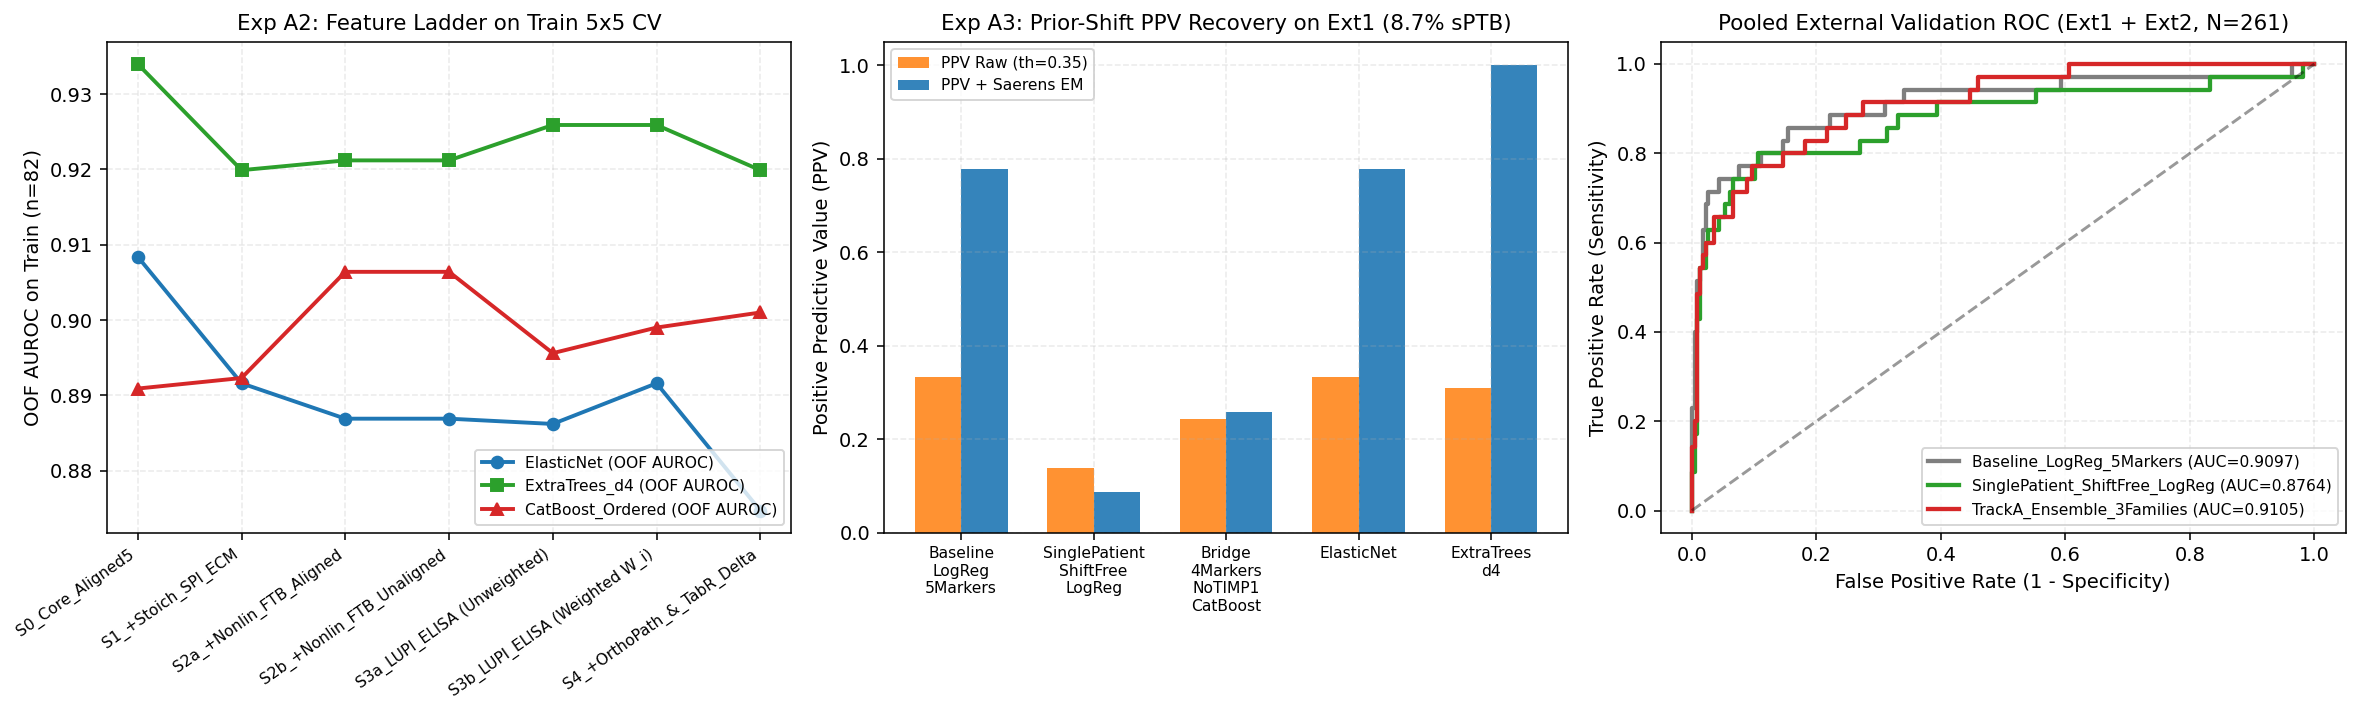

[SAVED FIGURE] artifacts/figures/TrackA_Summary_Diagnostics.png

[TRACK A COMPLETE] Все артефакты сохранены в /content/artifacts/track_a


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

ax = axes[0]
for fam, marker, color in [
    ("ElasticNet", "o", "#1f77b4"),
    ("ExtraTrees_d4", "s", "#2ca02c"),
    ("CatBoost_Ordered", "^", "#d62728"),
]:
    sub = df_a2_cv[df_a2_cv["Model"] == fam]
    x_pos = np.arange(len(sub))
    ax.plot(x_pos, sub["OOF_AUROC"], marker=marker, lw=2, color=color, label=f"{fam} (OOF AUROC)")
ax.set_xticks(np.arange(len(ladder_steps)))
ax.set_xticklabels([s[0].replace("Step", "S") for s in ladder_steps], rotation=35, ha="right", fontsize=8)
ax.set_ylabel("OOF AUROC on Train (n=82)")
ax.set_title("Exp A2: Feature Ladder on Train 5x5 CV")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
sub_ext1 = df_a3_exam[df_a3_exam["Cohort"] == "External_Val1 (n=127, 8.7% sPTB)"].iloc[:5]
x_m = np.arange(len(sub_ext1))
w_bar = 0.35
ax.bar(x_m - w_bar / 2, sub_ext1["PPV_Raw"], width=w_bar, color="#ff7f0e", alpha=0.85, label="PPV Raw (th=0.35)")
ax.bar(x_m + w_bar / 2, sub_ext1["PPV_SaerensEM"], width=w_bar, color="#1f77b4", alpha=0.9, label="PPV + Saerens EM")
ax.set_xticks(x_m)
ax.set_xticklabels([m.replace("TrackA_Best_", "").replace("_", "\n") for m in sub_ext1["Model"]], fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Positive Predictive Value (PPV)")
ax.set_title("Exp A3: Prior-Shift PPV Recovery on Ext1 (8.7% sPTB)")
ax.legend(fontsize=8)

ax = axes[2]
ext_pool_mask = m_ext1 | m_ext2
y_ext_pool = y_holdout[ext_pool_mask]
for label_plot, color in [
    ("Baseline_LogReg_5Markers", "#7f7f7f"),
    ("SinglePatient_ShiftFree_LogReg", "#2ca02c"),
    ("TrackA_Ensemble_3Families", "#d62728"),
]:
    probs_plot = final_candidates_a[label_plot]["test_probs_bagged"][ext_pool_mask]
    fpr, tpr, _ = roc_curve(y_ext_pool, probs_plot)
    auc_v = roc_auc_score(y_ext_pool, probs_plot)
    ax.plot(fpr, tpr, lw=2.2, color=color, label=f"{label_plot} (AUC={auc_v:.4f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.set_title("Pooled External Validation ROC (Ext1 + Ext2, N=261)")
ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
fig_path = FIGURES_DIR / "TrackA_Summary_Diagnostics.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[SAVED FIGURE] {fig_path}")

holdout_sample_ids = cohort_a.index[holdout_mask]
train_sample_ids = cohort_a.index[train_mask]

for cand_label, cand_obj in final_candidates_a.items():
    safe_name = cand_label.replace(" ", "_").replace("|", "").replace("(", "").replace(")", "")
    oof_df = pd.DataFrame({
        "Sample_ID": train_sample_ids,
        "Target": y_train_82,
        "oof_prob": cand_obj["oof_probs"],
        "oof_logit": cand_obj["oof_logits"],
    }).set_index("Sample_ID")
    oof_df.to_parquet(TRACK_A_DIR / f"oof_{safe_name}.parquet")

    test_df = pd.DataFrame({
        "Sample_ID": holdout_sample_ids,
        "Dataset": ds_holdout,
        "Target": y_holdout,
        "test_prob_bagged": cand_obj["test_probs_bagged"],
        "test_logit_bagged": logit(np.clip(cand_obj["test_probs_bagged"], 1e-6, 1.0 - 1e-6)),
        "test_prob_refit": cand_obj["test_probs_refit"],
        "test_prob_bagged_saerens_em": cand_obj["test_probs_bagged_saerens_em"],
    }).set_index("Sample_ID")
    test_df.to_parquet(TRACK_A_DIR / f"test_{safe_name}.parquet")

df_a1_summary.to_csv(TRACK_A_DIR / "exp_a1_panels_summary.csv", index=False)
df_a2_cv.to_csv(TRACK_A_DIR / "exp_a2_feature_ladder_cv.csv", index=False)
df_a3_exam.to_csv(TRACK_A_DIR / "exp_a3_prior_shift_exam.csv", index=False)

print(f"\n[TRACK A COMPLETE] Все артефакты сохранены в {TRACK_A_DIR.resolve()}")